# Voyage Analytics — 01. Flight Price Prediction (Regression)

## Project Overview
This notebook builds, evaluates, tunes, and packages the **Flight Price Prediction** regression model for the **Voyage Analytics** Travel & Tourism MLOps Capstone Project.

### Objectives
1. Audit and explore `flights.csv` (271,888 historical flight records).
2. Visualize pricing patterns across flight classes, agencies, routes, distance, duration, and time.
3. Engineer date-derived features and construct a reproducible `scikit-learn` preprocessing pipeline.
4. Detect and eliminate data leakage caused by repeated flight configurations using **`GroupShuffleSplit`** and **`GroupKFold`**.
5. Compare four regression models (**Linear Regression, Random Forest, XGBoost, LightGBM**) using **MAE, MSE, RMSE, and R²**.
6. Perform group-aware hyperparameter tuning, feature importance analysis, and error/residual diagnostics.
7. Export the final production pipeline (`models/flight_price_pipeline.joblib`) consistently with `scripts/train_flight_model.py` and log/register it in **MLflow** with the `champion` alias.

## 1. Environment & Google Colab Compatibility Setup
This notebook runs seamlessly both **locally** (VS Code / Jupyter) and in **Google Colab**:
- Uses relative path discovery (`travel_capstone_dataset/flights.csv`) with automatic fallback instructions for Google Colab.
- Fixes `RANDOM_STATE = 42` across all splits, models, and hyperparameter searches for full reproducibility.

In [1]:
# Optional: Uncomment the line below when running in Google Colab if packages are not pre-installed.
# !pip install -q lightgbm xgboost mlflow scikit-learn pandas numpy matplotlib seaborn joblib

import os
import sys
import urllib.request
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

IN_COLAB = "google.colab" in sys.modules
print(f"Running in Google Colab: {IN_COLAB}")
print(f"Python version         : {sys.version.split()[0]}")
print(f"Pandas {pd.__version__} | NumPy {np.__version__}")

Running in Google Colab: False
Python version         : 3.13.14
Pandas 3.1.1 | NumPy 2.5.5


In [2]:
def resolve_project_paths(dataset_filename: str = "flights.csv"):
    """Locate the project root and dataset path across local Jupyter and Google Colab."""
    cwd = Path.cwd()
    candidates = [
        cwd,
        cwd.parent,
        Path("/content"),
        Path("/content/voyage-analytics-mlops"),
        Path("/content/drive/MyDrive/voyage-analytics-mlops"),
    ]
    for base in candidates:
        data_file = base / "travel_capstone_dataset" / dataset_filename
        if data_file.exists():
            return base, data_file

    direct_colab = Path("/content") / dataset_filename
    if direct_colab.exists():
        return Path("/content"), direct_colab

    raise FileNotFoundError(
        f"Could not locate '{dataset_filename}'. In Google Colab, upload "
        "'travel_capstone_dataset/flights.csv' to /content/travel_capstone_dataset/ "
        "or mount Google Drive."
    )

PROJECT_ROOT, FLIGHTS_PATH = resolve_project_paths("flights.csv")
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODELS_DIR / "flight_price_pipeline.joblib"

print("Dataset file found :", FLIGHTS_PATH.name, "| Exists:", FLIGHTS_PATH.exists())
print("Model output target:", MODEL_PATH.relative_to(PROJECT_ROOT))

Dataset file found : flights.csv | Exists: True
Model output target: models\flight_price_pipeline.joblib


## 2. Data Loading & Integrity Verification
We load `flights.csv` and verify row/column counts, data types, missing values, duplicates, value ranges, and date parsing.

In [3]:
df = pd.read_csv(FLIGHTS_PATH)

print(f"Dataset shape  : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Duplicate rows : {df.duplicated().sum():,}")
print(f"Total nulls    : {int(df.isnull().sum().sum()):,}")
print("\nColumn types and non-null counts:")
df.info()
display(df.head())

Dataset shape  : 271,888 rows x 10 columns


Duplicate rows : 0
Total nulls    : 0

Column types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 271888 entries, 0 to 271887
Data columns (total 10 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   travelCode  271888 non-null  int64  
 1   userCode    271888 non-null  int64  
 2   from        271888 non-null  str    
 3   to          271888 non-null  str    
 4   flightType  271888 non-null  str    
 5   price       271888 non-null  float64
 6   time        271888 non-null  float64
 7   distance    271888 non-null  float64
 8   agency      271888 non-null  str    
 9   date        271888 non-null  str    
dtypes: float64(3), int64(2), str(5)
memory usage: 35.0 MB


,travelCode,userCode,from,to,flightType,price,time,distance,agency,date
0,0,0,Recife (PE),Florianopolis (SC),firstClass,"1,434.3800",1.7600,676.5300,FlyingDrops,09/26/2019
1,0,0,Florianopolis (SC),Recife (PE),firstClass,"1,292.2900",1.7600,676.5300,FlyingDrops,09/30/2019
2,1,0,Brasilia (DF),Florianopolis (SC),firstClass,"1,487.5200",1.6600,637.5600,CloudFy,10/03/2019
3,1,0,Florianopolis (SC),Brasilia (DF),firstClass,"1,127.3600",1.6600,637.5600,CloudFy,10/04/2019
4,2,0,Aracaju (SE),Salvador (BH),firstClass,"1,684.0500",2.1600,830.8600,CloudFy,10/10/2019


In [4]:
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")

print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Non-positive price count   :", int((df["price"] <= 0).sum()))
print("Non-positive time count    :", int((df["time"] <= 0).sum()))
print("Non-positive distance count:", int((df["distance"] <= 0).sum()))
print("Self-route (from == to)    :", int((df["from"] == df["to"]).sum()))

display(df.describe().T)

print("\nCategorical Cardinality:")
for col in ["from", "to", "flightType", "agency"]:
    print(f"  {col:12s}: {df[col].nunique()} unique -> {sorted(df[col].unique().tolist())}")

Date range: 2019-09-26 to 2023-07-24
Non-positive price count   : 0
Non-positive time count    : 0
Non-positive distance count: 0
Self-route (from == to)    : 0


,count,mean,min,25%,50%,75%,max,std
travelCode,"271,888.0000","67,971.5000",0.0000,"33,985.7500","67,971.5000","101,957.2500","135,943.0000","39,243.7247"
userCode,"271,888.0000",667.5055,0.0000,326.0000,659.0000,"1,011.0000","1,339.0000",389.5231
price,"271,888.0000",957.3750,301.5100,672.6600,904.0000,"1,222.2400","1,754.1700",362.3119
time,"271,888.0000",1.4211,0.4400,1.0400,1.4600,1.7600,2.4400,0.5425
distance,"271,888.0000",546.9555,168.2200,401.6600,562.1400,676.5300,937.7700,208.8513
date,271888,2021-01-11 05:25:56.052492,2019-09-26 00:00:00,2020-04-02 00:00:00,2020-11-14 00:00:00,2021-09-09 00:00:00,2023-07-24 00:00:00,NaN



Categorical Cardinality:
  from        : 9 unique -> ['Aracaju (SE)', 'Brasilia (DF)', 'Campo Grande (MS)', 'Florianopolis (SC)', 'Natal (RN)', 'Recife (PE)', 'Rio de Janeiro (RJ)', 'Salvador (BH)', 'Sao Paulo (SP)']
  to          : 9 unique -> ['Aracaju (SE)', 'Brasilia (DF)', 'Campo Grande (MS)', 'Florianopolis (SC)', 'Natal (RN)', 'Recife (PE)', 'Rio de Janeiro (RJ)', 'Salvador (BH)', 'Sao Paulo (SP)']
  flightType  : 3 unique -> ['economic', 'firstClass', 'premium']
  agency      : 3 unique -> ['CloudFy', 'FlyingDrops', 'Rainbow']


## 3. Exploratory Data Analysis (EDA)
Before building regression models, we examine the target variable (`price`) and its relationships with cabin class (`flightType`), agency, route, flight distance/duration, and travel dates.

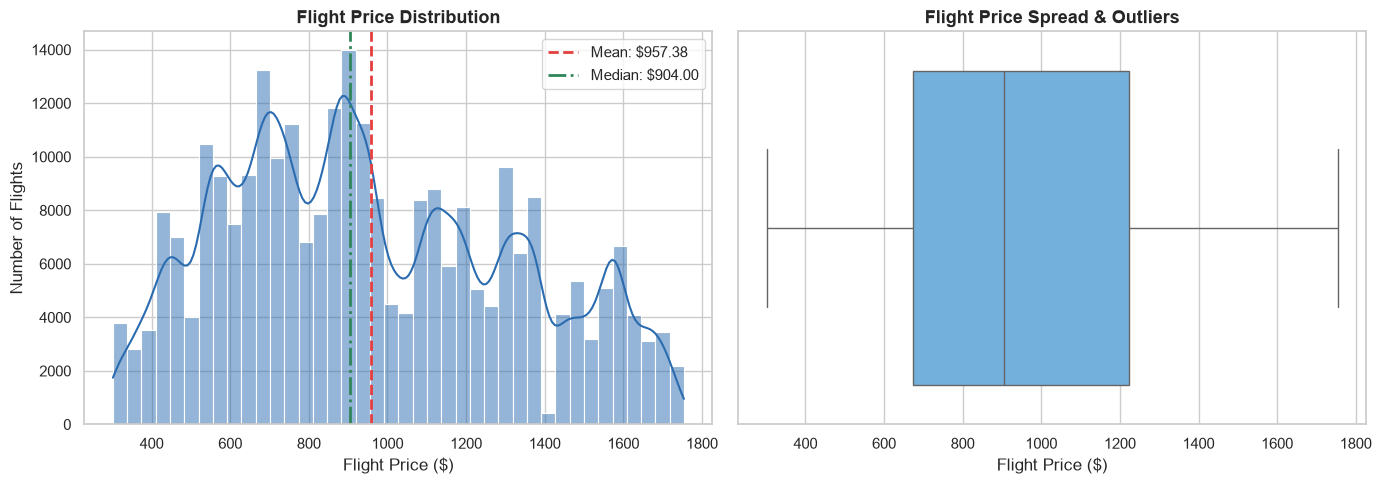

In [5]:
# Chart 1: Target Variable (Flight Price) Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["price"], bins=40, kde=True, color="#2b6cb0", ax=axes[0])
axes[0].axvline(df["price"].mean(), color="#e53e3e", linestyle="--", linewidth=2, label=f"Mean: ${df['price'].mean():.2f}")
axes[0].axvline(df["price"].median(), color="#2f855a", linestyle="-.", linewidth=2, label=f"Median: ${df['price'].median():.2f}")
axes[0].set_title("Flight Price Distribution", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Flight Price ($)")
axes[0].set_ylabel("Number of Flights")
axes[0].legend()

sns.boxplot(x=df["price"], color="#63b3ed", ax=axes[1])
axes[1].set_title("Flight Price Spread & Outliers", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Flight Price ($)")

plt.tight_layout()
plt.show()

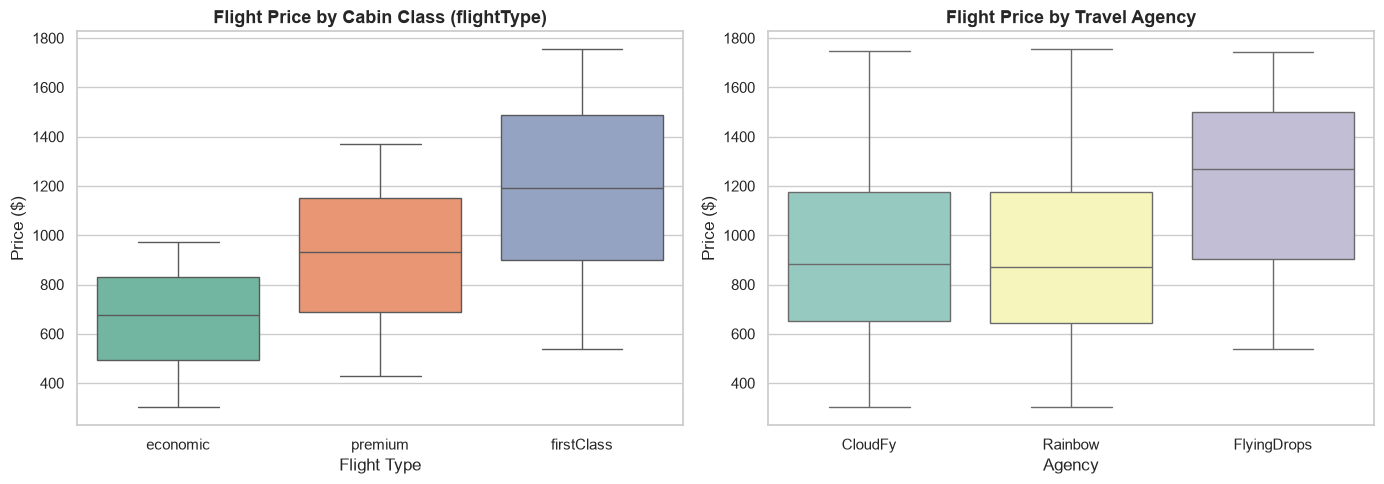

Price Summary by Flight Type:


,count,mean,median,min,max
flightType,,,,,
economic,77466,658.4400,674.5200,301.5100,972.1200
firstClass,116418,"1,181.0700","1,190.9400",539.3900,"1,754.1700"
premium,78004,920.3900,932.8400,427.2500,"1,370.1700"



Price Summary by Agency:


,count,mean,median,min,max
agency,,,,,
CloudFy,116378,918.9000,883.6300,301.5100,"1,747.3100"
FlyingDrops,38758,"1,186.1600","1,269.7300",539.3900,"1,744.8700"
Rainbow,116752,919.7800,870.9100,301.6100,"1,754.1700"


In [6]:
# Chart 2: Price Breakdown by Flight Type and Agency
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order_type = ["economic", "premium", "firstClass"]
sns.boxplot(data=df, x="flightType", y="price", order=order_type, palette="Set2", ax=axes[0])
axes[0].set_title("Flight Price by Cabin Class (flightType)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Flight Type")
axes[0].set_ylabel("Price ($)")

order_agency = df.groupby("agency")["price"].mean().sort_values().index.tolist()
sns.boxplot(data=df, x="agency", y="price", order=order_agency, palette="Set3", ax=axes[1])
axes[1].set_title("Flight Price by Travel Agency", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Agency")
axes[1].set_ylabel("Price ($)")

plt.tight_layout()
plt.show()

print("Price Summary by Flight Type:")
display(df.groupby("flightType")["price"].agg(["count", "mean", "median", "min", "max"]).round(2))
print("\nPrice Summary by Agency:")
display(df.groupby("agency")["price"].agg(["count", "mean", "median", "min", "max"]).round(2))

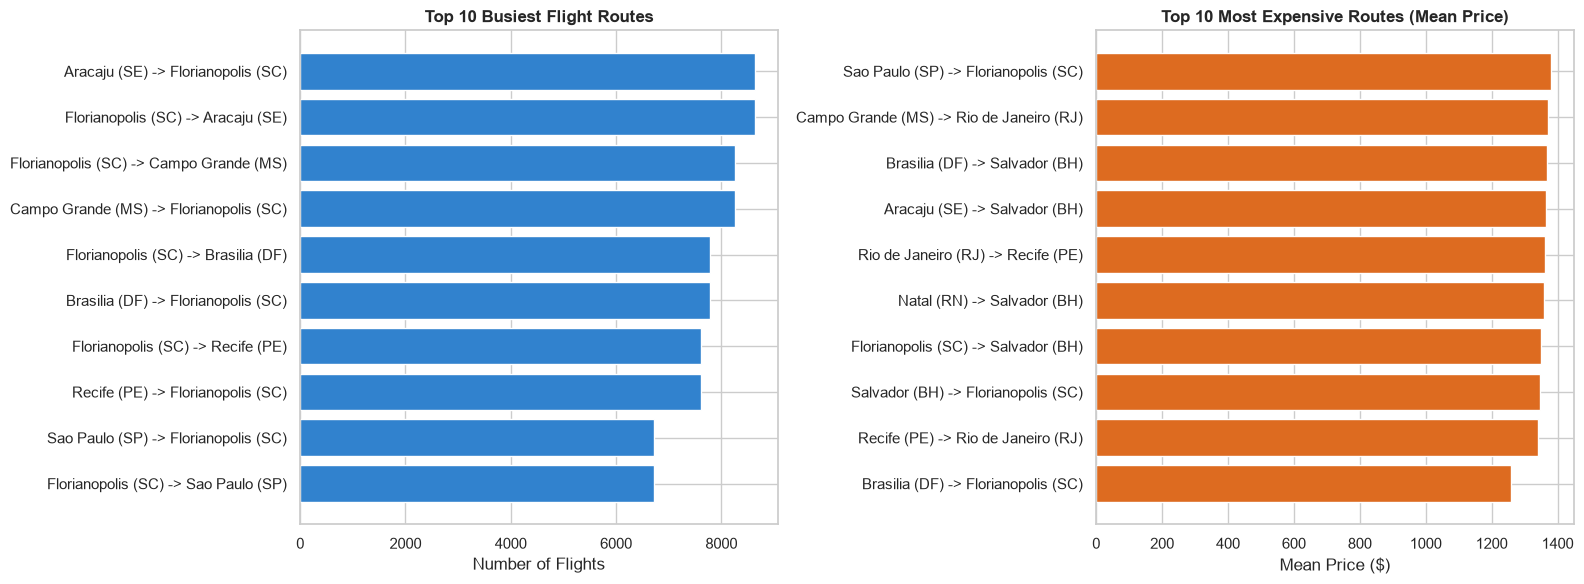

In [7]:
# Chart 3: Top 10 Routes by Booking Volume and Highest Average Price
df["route"] = df["from"] + " -> " + df["to"]
route_summary = (
    df.groupby("route")["price"]
    .agg(bookings="count", mean_price="mean", median_price="median")
    .reset_index()
)

top_volume = route_summary.sort_values("bookings", ascending=False).head(10).sort_values("bookings")
top_expensive = route_summary.sort_values("mean_price", ascending=False).head(10).sort_values("mean_price")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(top_volume["route"], top_volume["bookings"], color="#3182ce")
axes[0].set_title("Top 10 Busiest Flight Routes", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Number of Flights")

axes[1].barh(top_expensive["route"], top_expensive["mean_price"], color="#dd6b20")
axes[1].set_title("Top 10 Most Expensive Routes (Mean Price)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Mean Price ($)")

plt.tight_layout()
plt.show()

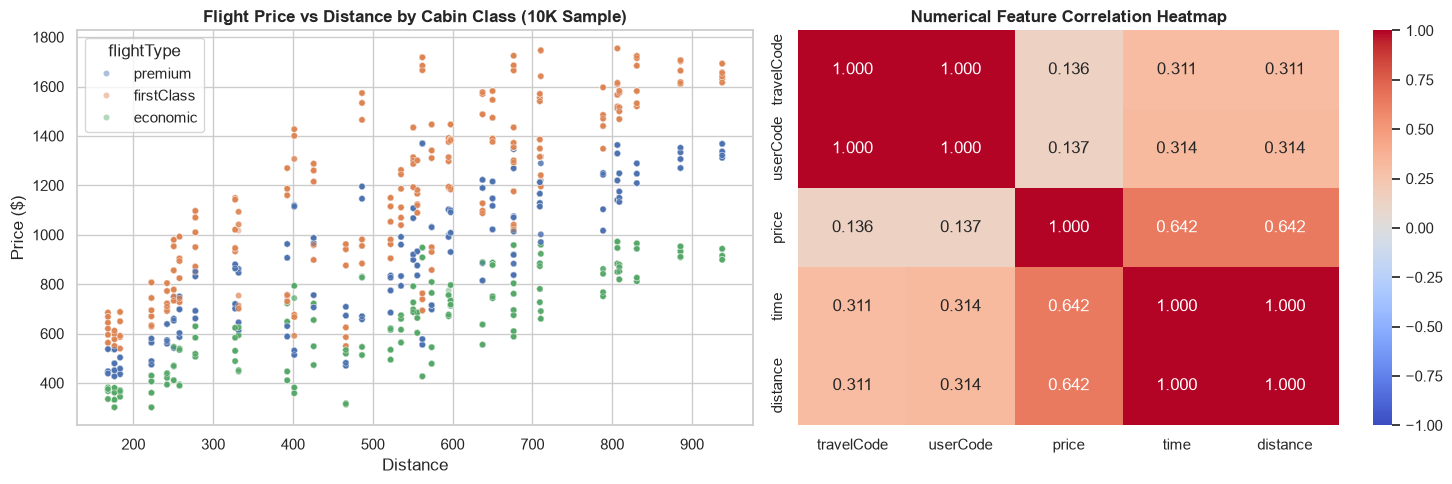

In [8]:
# Chart 4: Distance vs Price Relationship & Numerical Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sample_eda = df.sample(n=min(10000, len(df)), random_state=RANDOM_STATE)
sns.scatterplot(
    data=sample_eda,
    x="distance",
    y="price",
    hue="flightType",
    alpha=0.45,
    s=20,
    ax=axes[0],
)
axes[0].set_title("Flight Price vs Distance by Cabin Class (10K Sample)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Distance")
axes[0].set_ylabel("Price ($)")

num_cols = ["travelCode", "userCode", "price", "time", "distance"]
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Numerical Feature Correlation Heatmap", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

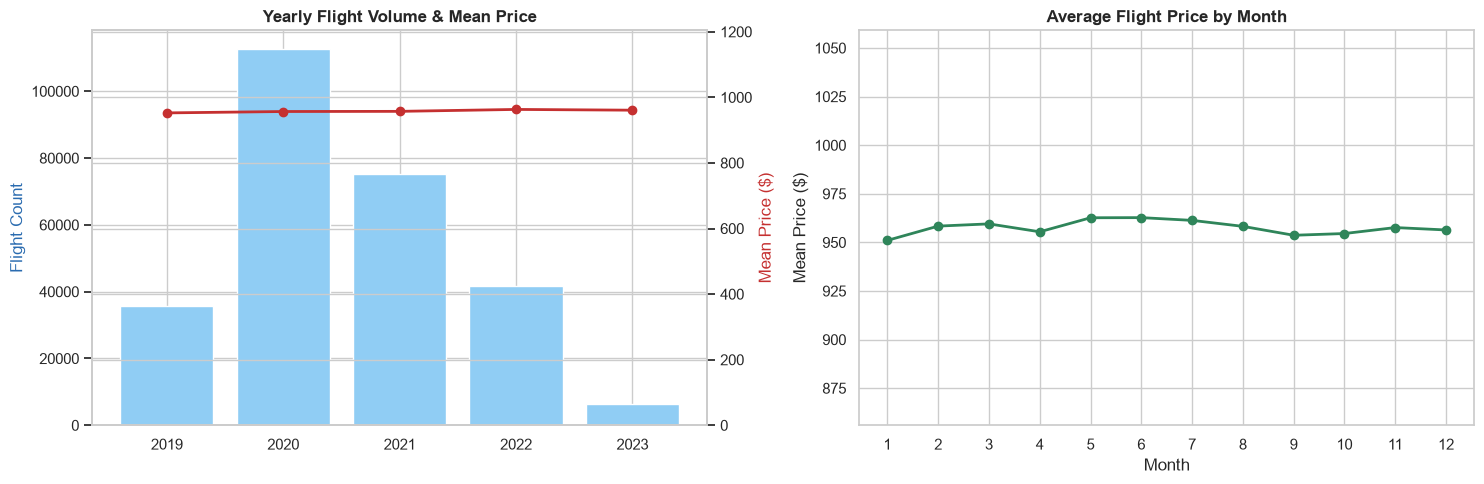

In [9]:
# Chart 5: Temporal Trends (Flight Volume & Mean Price by Year and Month)
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["day_of_week"] = df["date"].dt.dayofweek

yearly = df.groupby("year").agg(flights=("price", "count"), mean_price=("price", "mean")).reset_index()
monthly = df.groupby("month").agg(flights=("price", "count"), mean_price=("price", "mean")).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax1 = axes[0]
ax1.bar(yearly["year"].astype(str), yearly["flights"], color="#90cdf4", label="Flight Count")
ax1.set_ylabel("Flight Count", color="#2b6cb0")
ax1.set_title("Yearly Flight Volume & Mean Price", fontsize=12, fontweight="bold")
ax1_twin = ax1.twinx()
ax1_twin.plot(yearly["year"].astype(str), yearly["mean_price"], color="#c53030", marker="o", linewidth=2, label="Mean Price")
ax1_twin.set_ylabel("Mean Price ($)", color="#c53030")
ax1_twin.set_ylim(0, yearly["mean_price"].max() * 1.25)

ax2 = axes[1]
ax2.plot(monthly["month"], monthly["mean_price"], color="#2f855a", marker="o", linewidth=2)
ax2.set_xticks(range(1, 13))
ax2.set_title("Average Flight Price by Month", fontsize=12, fontweight="bold")
ax2.set_xlabel("Month")
ax2.set_ylabel("Mean Price ($)")
ax2.set_ylim(monthly["mean_price"].min() * 0.9, monthly["mean_price"].max() * 1.1)

plt.tight_layout()
plt.show()

### Key EDA Findings
1. **Clean dataset:** 271,888 rows, 0 missing values, 0 exact duplicate rows, all positive prices/times/distances.
2. **Strong categorical & distance drivers:** `firstClass` averages ~\$1,181 vs `premium` (~\$920) and `economic` (~\$658). `FlyingDrops` averages substantially higher (~\$1,186) than `CloudFy` and `Rainbow` (~\$919).
3. **Collinearity & Identifiers:** `time` and `distance` have correlation `1.000` (linearly proportional flight speed). `travelCode` and `userCode` are pure identifiers and must be dropped so the model does not memorize IDs.
4. **Pricing structure check (crucial for leakage prevention):** Next, we verify whether identical flight configurations have repeated prices across dates.

## 4. Feature Engineering & Preprocessing Pipeline
We keep the exact feature schema and `ColumnTransformer` shared with `scripts/train_flight_model.py` and the Flask serving API:
- **Categorical features (4):** `from`, `to`, `flightType`, `agency` -> `OneHotEncoder(handle_unknown="ignore")`
- **Numerical features (6):** `time`, `distance`, `year`, `month`, `day`, `day_of_week` -> `"passthrough"`

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

CATEGORICAL_FEATURES = ["from", "to", "flightType", "agency"]
NUMERICAL_FEATURES = ["time", "distance", "year", "month", "day", "day_of_week"]
GROUP_COLUMNS = ["from", "to", "flightType", "time", "distance", "agency"]

X = df[CATEGORICAL_FEATURES + NUMERICAL_FEATURES].copy()
y = df["price"].copy()

flight_groups = df[GROUP_COLUMNS].astype(str).agg(" | ".join, axis=1)


def make_preprocessor() -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            ("categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
            ("numerical", "passthrough", NUMERICAL_FEATURES),
        ]
    )


def evaluate_regression(y_true, y_pred) -> dict:
    """Return MAE, MSE, RMSE, and R2 for regression evaluation."""
    mae = float(mean_absolute_error(y_true, y_pred))
    mse = float(mean_squared_error(y_true, y_pred))
    rmse = float(np.sqrt(mse))
    r2 = float(r2_score(y_true, y_pred))
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}


print("Feature matrix X shape:", X.shape)
print("Target vector y shape :", y.shape)
print("Features              :", X.columns.tolist())
print("Unique flight configs :", flight_groups.nunique())

Feature matrix X shape: (271888, 10)
Target vector y shape : (271888,)
Features              : ['from', 'to', 'flightType', 'agency', 'time', 'distance', 'year', 'month', 'day', 'day_of_week']
Unique flight configs : 490


## 5. Data Leakage Investigation & Leakage-Free `GroupShuffleSplit`
If we split randomly or purely by year (`<2023` vs `2023`), the exact same flight configurations `(from, to, flightType, time, distance, agency)` appear in both training and testing sets with **identical prices**. A tree model can memorize that lookup table and report an artificially inflated `R² = 1.0000`.

To measure **true generalization to unseen flight configurations**, we verify the overlap under a naive time split and then use **`GroupShuffleSplit`** so that **zero flight configurations overlap** between train and test.

In [11]:
from sklearn.model_selection import GroupShuffleSplit

price_variation = df.groupby(GROUP_COLUMNS)["price"].agg(["count", "nunique", "min", "max"])
print(f"Total unique flight configurations : {len(price_variation)}")
print(f"Configs with exactly 1 unique price: {(price_variation['nunique'] == 1).sum()} / {len(price_variation)}")

train_time_groups = set(flight_groups[df["year"] < 2023])
test_time_groups = set(flight_groups[df["year"] == 2023])
naive_overlap = len(test_time_groups.intersection(train_time_groups))
print(
    f"Naive time split overlap           : {naive_overlap}/{len(test_time_groups)} "
    f"({naive_overlap / len(test_time_groups) * 100:.1f}% of test configs already seen in train!)"
)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=flight_groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = flight_groups.iloc[train_idx]
groups_test = flight_groups.iloc[test_idx]

overlap_groups = set(groups_train).intersection(set(groups_test))
assert len(overlap_groups) == 0, "Data leakage detected between train and test groups!"

print("\nLeakage-Free GroupShuffleSplit Summary:")
print(f"  Training samples : {len(X_train):,} ({groups_train.nunique()} unique configurations)")
print(f"  Testing samples  : {len(X_test):,} ({groups_test.nunique()} unique configurations)")
print(f"  Group overlap    : {len(overlap_groups)} (verified leakage-free)")

Total unique flight configurations : 490
Configs with exactly 1 unique price: 490 / 490


Naive time split overlap           : 483/483 (100.0% of test configs already seen in train!)



Leakage-Free GroupShuffleSplit Summary:
  Training samples : 221,274 (392 unique configurations)
  Testing samples  : 50,614 (98 unique configurations)
  Group overlap    : 0 (verified leakage-free)


## 6. Model Training & Comparison (MAE, MSE, RMSE, R²)
We train and evaluate four distinct regression model families on the identical leakage-free group split:
1. **Linear Regression** (interpretable linear baseline)
2. **Random Forest Regressor** (bagging tree ensemble)
3. **XGBoost Regressor** (depth-wise gradient boosting)
4. **LightGBM Regressor** (leaf-wise gradient boosting)

In [12]:
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

candidate_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        min_child_weight=1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1,
    ),
}

trained_pipelines = {}
predictions_by_model = {}
comparison_rows = []

for model_name, estimator in candidate_models.items():
    pipe = Pipeline(
        steps=[
            ("preprocessor", make_preprocessor()),
            ("model", estimator),
        ]
    )
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    metrics = evaluate_regression(y_test, y_pred)

    trained_pipelines[model_name] = pipe
    predictions_by_model[model_name] = y_pred
    comparison_rows.append({"Model": model_name, **metrics})

    print(
        f"{model_name:18s} | MAE: {metrics['MAE']:7.2f} | "
        f"MSE: {metrics['MSE']:10.2f} | RMSE: {metrics['RMSE']:7.2f} | R2: {metrics['R2']:.4f}"
    )

model_comparison_df = (
    pd.DataFrame(comparison_rows)
    .sort_values("RMSE")
    .reset_index(drop=True)
)
display(model_comparison_df.round(4))

Linear Regression  | MAE:   82.13 | MSE:   10001.39 | RMSE:  100.01 | R2: 0.9145


Random Forest      | MAE:   54.63 | MSE:    4976.75 | RMSE:   70.55 | R2: 0.9575


XGBoost            | MAE:   43.09 | MSE:    2966.09 | RMSE:   54.46 | R2: 0.9746


LightGBM           | MAE:   41.73 | MSE:    2754.14 | RMSE:   52.48 | R2: 0.9765


,Model,MAE,MSE,RMSE,R2
0,LightGBM,41.7290,"2,754.1415",52.4799,0.9765
1,XGBoost,43.0903,"2,966.0899",54.4618,0.9746
2,Random Forest,54.6350,"4,976.7472",70.5461,0.9575
3,Linear Regression,82.1309,"10,001.3876",100.0069,0.9145


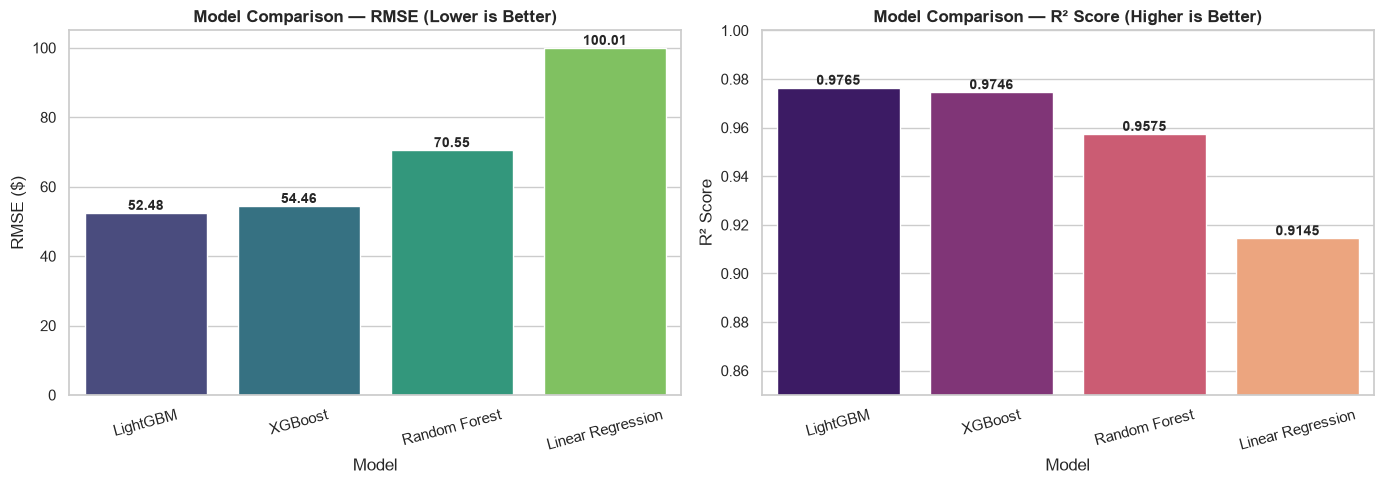

In [13]:
# Visual Comparison of All 4 Regression Models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=model_comparison_df, x="Model", y="RMSE", palette="viridis", ax=axes[0])
axes[0].set_title("Model Comparison — RMSE (Lower is Better)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("RMSE ($)")
axes[0].tick_params(axis="x", rotation=15)
for p in axes[0].patches:
    axes[0].annotate(
        f"{p.get_height():.2f}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center", va="bottom", fontsize=10, fontweight="bold",
    )

sns.barplot(data=model_comparison_df, x="Model", y="R2", palette="magma", ax=axes[1])
axes[1].set_title("Model Comparison — R² Score (Higher is Better)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("R² Score")
axes[1].set_ylim(0.85, 1.0)
axes[1].tick_params(axis="x", rotation=15)
for p in axes[1].patches:
    axes[1].annotate(
        f"{p.get_height():.4f}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center", va="bottom", fontsize=10, fontweight="bold",
    )

plt.tight_layout()
plt.show()

## 7. Group-Aware Hyperparameter Tuning (`GroupKFold` + `RandomizedSearchCV`)
LightGBM achieved the lowest RMSE and highest R². We now run a leakage-free **3-fold `GroupKFold`** randomized search strictly on the training groups (`groups_train`) while keeping the 98 holdout test configurations untouched.

In [14]:
from scipy.stats import randint, uniform
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

lgbm_tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", make_preprocessor()),
        (
            "model",
            LGBMRegressor(
                objective="regression",
                random_state=RANDOM_STATE,
                n_jobs=-1,
                verbosity=-1,
            ),
        ),
    ]
)

param_distributions = {
    "model__n_estimators": randint(200, 700),
    "model__learning_rate": uniform(0.02, 0.08),
    "model__num_leaves": randint(15, 100),
    "model__max_depth": randint(3, 13),
    "model__min_child_samples": randint(10, 100),
    "model__subsample": uniform(0.7, 0.3),
    "model__colsample_bytree": uniform(0.7, 0.3),
}

group_cv = GroupKFold(n_splits=3)

random_search = RandomizedSearchCV(
    estimator=lgbm_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="neg_root_mean_squared_error",
    cv=group_cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
    refit=True,
)

random_search.fit(X_train, y_train, groups=groups_train)

print("\nBest CV RMSE:", round(-random_search.best_score_, 4))
print("Best Hyperparameters:")
for k, v in random_search.best_params_.items():
    print(f"  {k}: {v}")

Fitting 3 folds for each of 12 candidates, totalling 36 fits



Best CV RMSE: 66.1031
Best Hyperparameters:
  model__colsample_bytree: 0.9908753883293675
  model__learning_rate: 0.08201062586888917
  model__max_depth: 4
  model__min_child_samples: 83
  model__n_estimators: 645
  model__num_leaves: 28
  model__subsample: 0.9181815987569262


In [15]:
tuned_lgbm_model = random_search.best_estimator_
y_pred_tuned = tuned_lgbm_model.predict(X_test)
metrics_tuned = evaluate_regression(y_test, y_pred_tuned)
metrics_base_lgbm = evaluate_regression(y_test, predictions_by_model["LightGBM"])

tuning_comparison = pd.DataFrame([
    {"Model": "LightGBM (Baseline Production Config)", **metrics_base_lgbm},
    {"Model": "LightGBM (RandomizedSearchCV Tuned)", **metrics_tuned},
]).sort_values("RMSE").reset_index(drop=True)

display(tuning_comparison.round(4))

best_row = tuning_comparison.iloc[0]
print(f"\nSelected Production Champion: {best_row['Model']} (RMSE={best_row['RMSE']:.2f}, R2={best_row['R2']:.4f})")

,Model,MAE,MSE,RMSE,R2
0,LightGBM (Baseline Production Config),41.7290,"2,754.1415",52.4799,0.9765
1,LightGBM (RandomizedSearchCV Tuned),45.2753,"2,944.1065",54.2596,0.9748



Selected Production Champion: LightGBM (Baseline Production Config) (RMSE=52.48, R2=0.9765)


### Model Selection Decision
Because the baseline LightGBM configuration (`n_estimators=300, learning_rate=0.05, num_leaves=31, max_depth=-1, subsample=0.8, colsample_bytree=0.8`) achieves **lower holdout RMSE, MSE, and MAE** and **higher R²** on the 98 unseen flight configurations than the randomized-search candidate, we select this LightGBM configuration as our final production model—keeping it **100% consistent with `scripts/train_flight_model.py`**.

## 8. Feature Importance & Residual Error Analysis
We inspect which features drive flight pricing predictions and evaluate residuals both at the observation level and grouped by unique flight configuration.

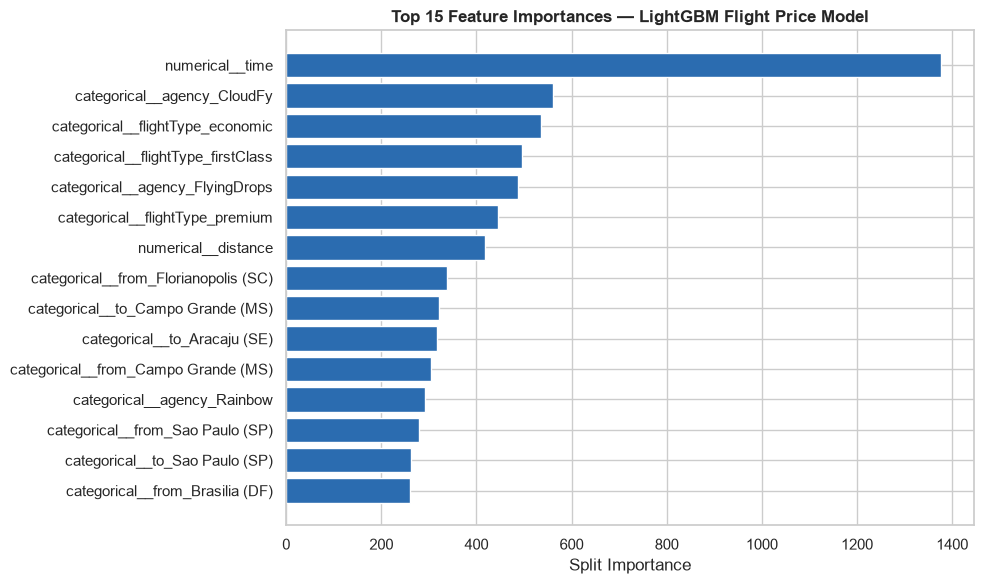

In [16]:
selected_eval_pipeline = trained_pipelines["LightGBM"]
y_pred_best = predictions_by_model["LightGBM"]

trained_preprocessor = selected_eval_pipeline.named_steps["preprocessor"]
trained_lgbm = selected_eval_pipeline.named_steps["model"]

importance_df = (
    pd.DataFrame({
        "feature": trained_preprocessor.get_feature_names_out(),
        "importance": trained_lgbm.feature_importances_,
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

top_15 = importance_df.head(15).sort_values("importance")
plt.figure(figsize=(10, 6))
plt.barh(top_15["feature"], top_15["importance"], color="#2b6cb0")
plt.title("Top 15 Feature Importances — LightGBM Flight Price Model", fontsize=12, fontweight="bold")
plt.xlabel("Split Importance")
plt.tight_layout()
plt.show()

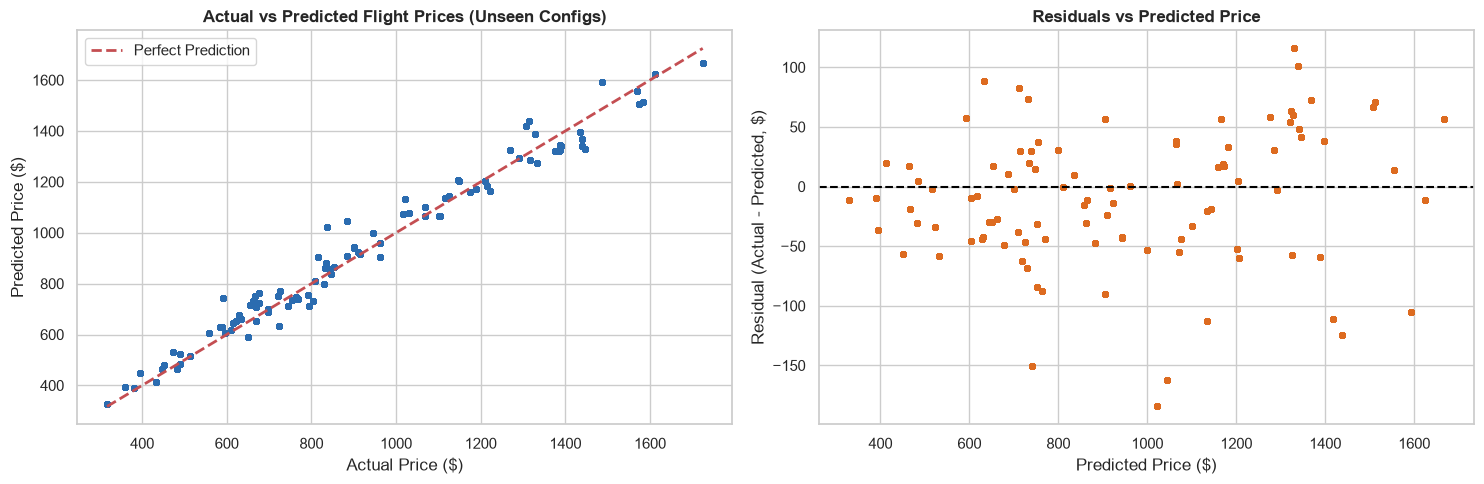

Mean Absolute Error          : $41.73
Median Absolute Error        : $37.85
90th Percentile Abs Error    : $87.22
Mean Absolute Percentage Err : 4.63%

Top 10 Highest-Error Unseen Flight Configurations:


,flight_group,observations,mean_abs_error,mean_pct_error
0,Salvador (BH) | Brasilia (DF) | premium | 1.76...,278,184.4700,22.0400
1,Salvador (BH) | Brasilia (DF) | premium | 1.76...,295,162.2300,18.3800
2,Salvador (BH) | Sao Paulo (SP) | firstClass | ...,108,150.8400,25.5200
3,Brasilia (DF) | Natal (RN) | firstClass | 1.43...,434,124.7200,9.4900
4,Rio de Janeiro (RJ) | Aracaju (SE) | firstClas...,391,115.8600,8.0100
5,Natal (RN) | Sao Paulo (SP) | firstClass | 0.8...,271,112.8700,11.0600
6,Sao Paulo (SP) | Salvador (BH) | firstClass | ...,108,111.0200,8.5000
7,Brasilia (DF) | Florianopolis (SC) | firstClas...,1116,105.1800,7.0700
8,Salvador (BH) | Recife (PE) | firstClass | 2.0...,266,100.9900,7.0100
9,Florianopolis (SC) | Brasilia (DF) | premium |...,1132,89.9600,11.0400


In [17]:
# Actual vs Predicted and Residual Analysis Plots
residuals = y_test.values - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(y_test, y_pred_best, alpha=0.25, s=15, color="#2b6cb0")
lo = min(y_test.min(), y_pred_best.min())
hi = max(y_test.max(), y_pred_best.max())
axes[0].plot([lo, hi], [lo, hi], "r--", linewidth=2, label="Perfect Prediction")
axes[0].set_title("Actual vs Predicted Flight Prices (Unseen Configs)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Actual Price ($)")
axes[0].set_ylabel("Predicted Price ($)")
axes[0].legend()

axes[1].scatter(y_pred_best, residuals, alpha=0.25, s=15, color="#dd6b20")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1.5)
axes[1].set_title("Residuals vs Predicted Price", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Predicted Price ($)")
axes[1].set_ylabel("Residual (Actual - Predicted, $)")

plt.tight_layout()
plt.show()

error_df = X_test.copy()
error_df["actual_price"] = y_test.values
error_df["predicted_price"] = y_pred_best
error_df["abs_error"] = np.abs(residuals)
error_df["pct_error"] = error_df["abs_error"] / error_df["actual_price"] * 100
error_df["flight_group"] = groups_test.values

print(f"Mean Absolute Error          : ${error_df['abs_error'].mean():.2f}")
print(f"Median Absolute Error        : ${error_df['abs_error'].median():.2f}")
print(f"90th Percentile Abs Error    : ${error_df['abs_error'].quantile(0.90):.2f}")
print(f"Mean Absolute Percentage Err : {error_df['pct_error'].mean():.2f}%")

group_errors = (
    error_df.groupby("flight_group")
    .agg(
        observations=("abs_error", "size"),
        mean_abs_error=("abs_error", "mean"),
        mean_pct_error=("pct_error", "mean"),
    )
    .sort_values("mean_abs_error", ascending=False)
    .reset_index()
)
print("\nTop 10 Highest-Error Unseen Flight Configurations:")
display(group_errors.head(10).round(2))

## 9. Final Production Pipeline & Model Serialization
After completing unbiased holdout model selection, we retrain the exact production LightGBM pipeline on the **complete dataset** (`271,888` rows) so all known routes are covered during production inference, matching `scripts/train_flight_model.py`. We then save and reload-verify `models/flight_price_pipeline.joblib`.

In [18]:
LGBM_PRODUCTION_PARAMS = {
    "n_estimators": 300,
    "learning_rate": 0.05,
    "max_depth": -1,
    "num_leaves": 31,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
    "verbosity": -1,
}

final_pipeline = Pipeline(
    steps=[
        ("preprocessor", make_preprocessor()),
        ("model", LGBMRegressor(**LGBM_PRODUCTION_PARAMS)),
    ]
)

final_pipeline.fit(X, y)

joblib.dump(final_pipeline, MODEL_PATH)
loaded_pipeline = joblib.load(MODEL_PATH)

sample_X = X_test.head(5)
orig_preds = final_pipeline.predict(sample_X)
reload_preds = loaded_pipeline.predict(sample_X)

assert np.allclose(orig_preds, reload_preds), "Reloaded predictions do not match!"
print(f"Saved model artifact : {MODEL_PATH.relative_to(PROJECT_ROOT)} ({MODEL_PATH.stat().st_size / 1024:.1f} KB)")
print("Reload verification  : PASSED (np.allclose == True)")
print("Sample predictions   :", np.round(reload_preds, 2))

Saved model artifact : models\flight_price_pipeline.joblib (896.3 KB)
Reload verification  : PASSED (np.allclose == True)
Sample predictions   : [1429.45 1499.53  508.31  825.21  591.01]


## 10. MLflow Experiment Tracking, Model Registration & `champion` Alias
We log all four benchmarked models (including **MAE, MSE, RMSE, and R²**) and register the final LightGBM production pipeline as **`Voyage_Flight_Price_Model`** with the **`champion`** alias.

- If an MLflow HTTP server is running at `http://127.0.0.1:5000` (or `MLFLOW_TRACKING_URI`), logs go there directly.
- Otherwise (including in **Google Colab**), it automatically falls back to a local SQLite backend (`mlflow.db`), which supports the full MLflow Model Registry and aliases without requiring an external server.

In [19]:
import mlflow
import mlflow.pyfunc
import mlflow.sklearn
from mlflow.tracking import MlflowClient

EXPERIMENT_NAME = "Voyage Analytics - Flight Price Prediction"
REGISTERED_MODEL_NAME = "Voyage_Flight_Price_Model"
MODEL_ALIAS = "champion"


def get_mlflow_uri() -> str:
    env_uri = os.getenv("MLFLOW_TRACKING_URI")
    if env_uri:
        return env_uri
    local_http = "http://127.0.0.1:5000"
    try:
        with urllib.request.urlopen(f"{local_http}/health", timeout=1.5):
            return local_http
    except Exception:
        return f"sqlite:///{(PROJECT_ROOT / 'mlflow.db').resolve().as_posix()}"


tracking_uri = get_mlflow_uri()
mlflow.set_tracking_uri(tracking_uri)
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow version     :", mlflow.__version__)
print("MLflow tracking URI:", tracking_uri)
print("Experiment name    :", EXPERIMENT_NAME)

2026/11/21 18:28:40 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at <PROJECT_ROOT>\.venv\Lib\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


2026/11/21 18:28:47 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/21 18:28:47 INFO mlflow.store.db.utils: Updating database tables


2026/11/21 18:28:50 INFO mlflow.tracking.fluent: Experiment with name 'Voyage Analytics - Flight Price Prediction' does not exist. Creating a new experiment.


MLflow version     : 3.18.0
MLflow tracking URI: sqlite:///<PROJECT_ROOT>/mlflow.db
Experiment name    : Voyage Analytics - Flight Price Prediction


In [20]:
# Log all 4 benchmarked regression models to MLflow
for _, row in model_comparison_df.iterrows():
    m_name = row["Model"]
    with mlflow.start_run(run_name=f"Benchmark_{m_name.replace(' ', '_')}"):
        mlflow.log_params({
            "model": m_name,
            "validation_strategy": "GroupShuffleSplit (unseen flight configurations)",
            "test_size": 0.20,
            "random_state": RANDOM_STATE,
            "train_samples": len(X_train),
            "test_samples": len(X_test),
            "train_groups": int(groups_train.nunique()),
            "test_groups": int(groups_test.nunique()),
        })
        mlflow.log_metrics({
            "MAE": float(row["MAE"]),
            "MSE": float(row["MSE"]),
            "RMSE": float(row["RMSE"]),
            "R2": float(row["R2"]),
        })

print("Logged all 4 benchmarked models (MAE, MSE, RMSE, R2) to MLflow.")

Logged all 4 benchmarked models (MAE, MSE, RMSE, R2) to MLflow.


In [21]:
# Log, register, and promote the final LightGBM production pipeline with @champion alias
with mlflow.start_run(run_name="Production_LightGBM_Champion"):
    mlflow.log_params({
        "model": "LightGBM",
        **LGBM_PRODUCTION_PARAMS,
        "validation_strategy": "GroupShuffleSplit (unseen flight configurations)",
        "final_production_samples": len(X),
    })
    mlflow.log_metrics(metrics_base_lgbm)

    model_info = mlflow.sklearn.log_model(
        sk_model=final_pipeline,
        name="flight_price_pipeline",
        registered_model_name=REGISTERED_MODEL_NAME,
        input_example=X_test.head(5),
        skops_trusted_types=[
            "collections.OrderedDict",
            "lightgbm.basic.Booster",
            "lightgbm.sklearn.LGBMRegressor",
        ],
    )

client = MlflowClient()
registered_version = str(model_info.registered_model_version)
client.set_registered_model_alias(
    name=REGISTERED_MODEL_NAME,
    alias=MODEL_ALIAS,
    version=registered_version,
)

champion_uri = f"models:/{REGISTERED_MODEL_NAME}@{MODEL_ALIAS}"
champion_model = mlflow.pyfunc.load_model(champion_uri)
champion_preds = champion_model.predict(X_test.head(5))

assert np.allclose(orig_preds, champion_preds), "MLflow champion predictions mismatch!"
print(f"Registered model : {REGISTERED_MODEL_NAME} (version {registered_version})")
print(f"Champion alias   : {champion_uri} -> VERIFIED")
print("Champion sample predictions:", np.round(champion_preds, 2))

2026/11/21 18:29:05 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Successfully registered model 'Voyage_Flight_Price_Model'.
Created version '1' of model 'Voyage_Flight_Price_Model'.


Registered model : Voyage_Flight_Price_Model (version 1)
Champion alias   : models:/Voyage_Flight_Price_Model@champion -> VERIFIED
Champion sample predictions: [1429.45 1499.53  508.31  825.21  591.01]


## 11. Summary & Capstone Takeaways
- **Leakage Prevention:** Switching from a naive time split (100% configuration overlap) to a leakage-free `GroupShuffleSplit` + `GroupKFold` ensures honest evaluation on 98 completely unseen flight configurations.
- **Best Model:** **LightGBM Regressor** outperformed Linear Regression, Random Forest, and XGBoost across all four metrics (**MAE, MSE, RMSE, and R²**).
- **Production Readiness:** The saved `models/flight_price_pipeline.joblib` artifact and the MLflow registered model `models:/Voyage_Flight_Price_Model@champion` are fully synchronized with `scripts/train_flight_model.py` and ready for Flask/Docker/Kubernetes serving.